# چالش ۳ — «تصمیم پرهزینه»: مدل نکول اعتباری

در این مرحله می‌خواهم پیش از اعطای وام، احتمال نکول جدی متقاضی در دو سال آینده را تخمین بزنم و آن را به یک تصمیم «تأیید / رد» تبدیل کنم. هدفم دقت بالا نیست، **کمترین هزینه کل** است:
- اگر کسی را تأیید کنم و نکول کند (FN)، ۱۲ واحد هزینه دارد.
- اگر فرد سالمی را رد کنم (FP)، ۱ واحد هزینه دارد.

**زنجیره داده:** فایل `cs-training.csv` را با همان package مراحل ۱ و ۲ (`data-factory run --dataset credit`) اعتبارسنجی و قرنطینه کردم و در schema `credit` از پایگاه داده `dba_stage2` بارگذاری کردم. این نوت‌بوک **هیچ CSV‌ای نمی‌خواند**؛ همه داده را از view `credit.model_input` و با SQLAlchemy می‌خوانم. منطق اصلی در `src/data_factory/credit_model.py` است و اینجا فقط آن را صدا می‌زنم و نتیجه را توضیح می‌دهم.

**بودجه زمانی:** کل مرحله ۶ تا ۸ روز کاری. اجرای کامل این نوت‌بوک روی سیستم من حدود ۶ دقیقه طول می‌کشد (سقف ۲۰ دقیقه است). تنها seed نوت‌بوک در سلول بعد تعریف می‌شود و از `factory.toml` می‌آید.

In [1]:
import time
NOTEBOOK_STARTED = time.perf_counter()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from sklearn.inspection import permutation_importance

from data_factory import credit_model as cm
from data_factory.config import load_config
from data_factory.credit_contract import TARGET
from data_factory.db import make_engine

config = load_config("factory.toml")
M = config.credit.model
SEED = M.seed                       # the one seed of this notebook
np.random.seed(SEED)
COST_FN, COST_FP = M.cost_fn, M.cost_fp
SCHEMA = config.credit.load.schema
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:.4f}".format)
print("seed", SEED, "| cost FN", COST_FN, "| cost FP", COST_FP, "| schema", SCHEMA)

seed 42 | cost FN 12.0 | cost FP 1.0 | schema credit


## ۱. خواندن داده از پایگاه داده

داده را از view `model_input` در چند chunk می‌خوانم و زمان خواندن را اندازه می‌گیرم. نوع ستون‌ها را در مرحله بارگذاری خودم طراحی کردم: شمارش‌ها `smallint`، و نسبت‌ها و درآمد `double precision`. اتصال را صریح باز می‌کنم و در پایان نوت‌بوک engine را می‌بندم.

In [2]:
engine = make_engine(config.database)
with engine.connect() as connection:
    data, read_stats = cm.read_model_input(connection, SCHEMA, config.clean.chunk_rows)
    load_run = connection.execute(text(
        "SELECT load_id, snapshot, loaded_at_utc FROM credit.load_runs ORDER BY loaded_at_utc DESC LIMIT 1")).one()
    column_types = pd.read_sql_query(text(
        "SELECT column_name, data_type FROM information_schema.columns "
        "WHERE table_schema = :s AND table_name = 'applicants' ORDER BY ordinal_position"),
        connection, params={"s": SCHEMA})
print("read:", read_stats)
print("last load:", dict(load_run._mapping))
column_types.T

read: {'rows': 150000, 'chunks': 3, 'seconds': 0.83}
last load: {'load_id': 'b10f64e4', 'snapshot': 'credit-3704777264b6', 'loaded_at_utc': datetime.datetime(2026, 11, 3, 15, 17, 43)}


,0,1,2,3,4,5,6,7,8,9,10,11
column_name,applicant_id,serious_dlq_2yrs,revolving_utilization,age,past_due_30_59,debt_ratio,monthly_income,open_credit_lines,past_due_90,real_estate_loans,past_due_60_89,dependents
data_type,integer,smallint,double precision,smallint,smallint,double precision,double precision,smallint,smallint,smallint,smallint,smallint


## ۲. شناخت dataset و برچسب

- **Samples:** هر سطر یک متقاضی است.
- **Target:** `serious_dlq_2yrs`، یعنی ۹۰ روز تأخیر یا بیشتر در دو سال بعد.
- **Features:** ده ستون ورودی. ظاهر همه عددی است، ولی سه ستون تأخیر پرداخت مقدارهای 96 و 98 دارند که **کد** هستند نه شمارش (بخش ۳). این کدها را در یک ستون دسته‌ای جدا (`past_due_code`) نگه داشتم. برچسب هم با اینکه عدد است، دسته‌ای (دودویی) است.

**از دیکشنری داده** (`Data Dictionary.xls`) این نکته‌ها را برداشتم:
- `RevolvingUtilizationOfUnsecuredLines` مانده کارت‌ها و خطوط اعتباری شخصی تقسیم بر مجموع سقف آن‌هاست، بدون وام مسکن و خودرو. پس مقدار کمی بالای ۱ ممکن است، ولی هزاران برابر ممکن نیست.
- `DebtRatio` مجموع پرداخت ماهانه بدهی تقسیم بر درآمد ماهانه است. پس بدون درآمد معنای خودش را از دست می‌دهد.
- ستون‌های تأخیر ۳۰–۵۹ و ۶۰–۸۹ روزه تعداد دفعات تأخیر در دو سال گذشته‌اند. ستون ۹۰ روزه بازه زمانی ندارد، ولی آن هم سابقه است. پس همه اطلاعاتی‌اند که **پیش از** درخواست وام وجود دارد.

**نوع یادگیری:** یادگیری نظارت‌شده، دسته‌بندی دودویی، چون برچسب تاریخی را دارم و فقط دو مقدار دارد.

In [3]:
kinds = pd.DataFrame({
    "kind": ["label (binary)"] + ["numeric"] * 10 + ["categorical (decoded codes)"],
    "missing": [data[c].isna().sum() for c in [TARGET] + cm.BASE_NUMERIC + cm.CATEGORICAL],
}, index=[TARGET] + cm.BASE_NUMERIC + cm.CATEGORICAL)
print("samples:", len(data), "| features:", 10, "| positives:", int(data[TARGET].sum()),
      f"({data[TARGET].mean():.2%})")
print(f"accuracy of 'approve everyone' (learns nothing): {1 - data[TARGET].mean():.2%}")
kinds

samples: 150000 | features: 10 | positives: 10026 (6.68%)
accuracy of 'approve everyone' (learns nothing): 93.32%


,kind,missing
serious_dlq_2yrs,label (binary),0
revolving_utilization,numeric,241
age,numeric,1
past_due_30_59,numeric,269
past_due_60_89,numeric,269
past_due_90,numeric,269
debt_ratio,numeric,0
monthly_income,numeric,29731
open_credit_lines,numeric,0
real_estate_loans,numeric,0


## ۳. مقادیر نگهبان (sentinel) و Outlierهای غیرممکن

جدول خام `applicants` را دقیقاً مثل منبع نگه داشتم. قاعده‌هایی که در view `model_input` گذاشتم این‌هاست:
- **96 و 98** در سه ستون تأخیر را کد سیستم منبع می‌دانم، چون مثلاً ۹۸ بار تأخیر ۶۰ تا ۸۹ روزه در دو سال ممکن نیست. شمارش را گمشده می‌کنم و کد را در `past_due_code` نگه می‌دارم.
- **سن صفر** برای وام‌گیرنده غیرممکن است و گمشده می‌شود.
- **utilization بالای ۱۰** یعنی مانده‌ای ده برابر سقف اعتبار. این را خطای داده می‌دانم و گمشده می‌کنم. مقدار بین ۱ و ۱۰ ممکن است (عبور از سقف)، پس آن را نگه می‌دارم.

**چرا این بخش را در پایگاه داده گذاشتم؟** این قاعده‌ها واقعیت‌هایی درباره منبع‌اند و برای هر کسی که داده را می‌خواند یکسان‌اند. چون هر سطر جداگانه بررسی می‌شود و از سطرهای دیگر چیزی یاد گرفته نمی‌شود، **نشت هم ایجاد نمی‌کنند**. هر چیزی که آمار یاد می‌گیرد (میانه، مقیاس، فهرست دسته‌ها) را در Python و فقط روی داده آموزش fit می‌کنم.

In [4]:
with engine.connect() as connection:
    sentinel = pd.read_sql_query(text('''
        SELECT 'past_due >= 96' AS rule, count(*) AS rows, avg(serious_dlq_2yrs) AS default_rate
          FROM credit.applicants WHERE greatest(past_due_30_59, past_due_60_89, past_due_90) >= 96
        UNION ALL SELECT 'age = 0', count(*), avg(serious_dlq_2yrs) FROM credit.applicants WHERE age = 0
        UNION ALL SELECT 'revolving_utilization > 10', count(*), avg(serious_dlq_2yrs)
          FROM credit.applicants WHERE revolving_utilization > 10
        UNION ALL SELECT 'revolving_utilization in (1, 10]', count(*), avg(serious_dlq_2yrs)
          FROM credit.applicants WHERE revolving_utilization > 1 AND revolving_utilization <= 10
        UNION ALL SELECT 'all applicants', count(*), avg(serious_dlq_2yrs) FROM credit.applicants'''), connection)
    codes = pd.read_sql_query(text(
        "SELECT past_due_30_59, past_due_60_89, past_due_90, count(*) AS rows FROM credit.applicants "
        "WHERE greatest(past_due_30_59, past_due_60_89, past_due_90) >= 96 GROUP BY 1, 2, 3"), connection)
    largest_real = connection.execute(text(
        "SELECT max(past_due_30_59) FILTER (WHERE past_due_30_59 < 96), max(past_due_60_89) FILTER (WHERE past_due_60_89 < 96), "
        "max(past_due_90) FILTER (WHERE past_due_90 < 96) FROM credit.applicants")).one()
print("largest real counts below the codes (30-59, 60-89, 90):", tuple(largest_real))
print(codes.to_string(index=False))
sentinel

largest real counts below the codes (30-59, 60-89, 90): (13, 11, 17)
 past_due_30_59  past_due_60_89  past_due_90  rows
             96              96           96     5
             98              98           98   264


,rule,rows,default_rate
0,age = 0,1,0.0000
1,revolving_utilization > 10,241,0.0705
2,all applicants,150000,0.0668
3,"revolving_utilization in (1, 10]",3080,0.3961
4,past_due >= 96,269,0.5465


در همه ۲۶۹ ردیف کددار، **هر سه** ستون همزمان همان کد را دارند و بزرگ‌ترین شمارش واقعی فقط 13، 11 و 17 است. پس این مقدارها شمارش نیستند. نرخ نکول این گروه (0.5465) هم خیلی بالاست، یعنی کد اطلاعات دارد و نباید دور ریخته شود. اگر 98 را عدد معمولی فرض می‌کردم، مدل خطی آن را «۹۸ بار تأخیر» می‌خواند.

## ۴. گمشده‌ها: آیا نبودِ مقدار خودش معنا دارد؟

مقدار گمشده فقط در `monthly_income` و `dependents` هست، به‌اضافه گمشده‌هایی که خودم در بخش ۳ ساختم. قبل از اینکه تصمیم بگیرم چطور پرشان کنم، بررسی می‌کنم که گمشدگی تصادفی است یا نه.

In [5]:
income_missing = data["monthly_income"].isna()
dependents_missing = data["dependents"].isna()
def rate_test(mask):
    a, b = data.loc[mask, TARGET], data.loc[~mask, TARGET]
    pooled = data[TARGET].mean()
    z = (a.mean() - b.mean()) / np.sqrt(pooled * (1 - pooled) * (1 / len(a) + 1 / len(b)))
    return a.mean(), b.mean(), z
rows = []
for name, mask in [("monthly_income missing", income_missing), ("dependents missing", dependents_missing)]:
    missing_rate, present_rate, z = rate_test(mask)
    rows.append({"column": name, "rows": int(mask.sum()), "default_rate_missing": missing_rate,
                 "default_rate_present": present_rate, "z": z,
                 "median_age_missing": data.loc[mask, "age"].median(), "median_age_present": data.loc[~mask, "age"].median(),
                 "median_debt_ratio_missing": data.loc[mask, "debt_ratio"].median(),
                 "median_debt_ratio_present": data.loc[~mask, "debt_ratio"].median()})
print("dependents missing -> income also missing:", int((dependents_missing & income_missing).sum()), "of", int(dependents_missing.sum()))
pd.DataFrame(rows).set_index("column").T

dependents missing -> income also missing: 3924 of 3924


column,monthly_income missing,dependents missing
rows,29731.0000,3924.0000
default_rate_missing,0.0561,0.0456
default_rate_present,0.0695,0.0674
z,-8.2527,-5.3943
median_age_missing,57.0000,61.0000
median_age_present,51.0000,52.0000
median_debt_ratio_missing,1159.0000,358.0000
median_debt_ratio_present,0.2960,0.3578


**نتیجه:** گمشدگی تصادفی **نیست**. شاهدهای عددی:
- نرخ نکول وقتی درآمد گمشده است 0.0561 و در بقیه 0.0695 است (z = −8.25).
- میانه سن این گروه 57 است در برابر 51.
- میانه `debt_ratio` این گروه 1159 است در برابر 0.296. یعنی وقتی درآمد ثبت نشده، منبع در ستون «نسبت بدهی» عملاً **مبلغ بدهی** را نوشته است.
- هر 3924 ردیفی که `dependents` ندارد، درآمد هم ندارد.

**اثر این نتیجه روی کار من:**
1. «گمشده بودن» را به‌صورت یک پرچم (indicator) به مدل می‌دهم.
2. ویژگی `debt_ratio_known_income` را می‌سازم که نسبت بدهی را فقط وقتی درآمد معلوم است نگه می‌دارد.

در بخش ۷ دو سیاست را با عدد مقایسه می‌کنم: **(الف)** میانه + پرچم، **(ب)** فقط میانه.

## ۵. تقسیم داده

این داده ستون زمان ندارد، پس تقسیم زمانی ممکن نیست. ۲۰٪ داده را به‌صورت stratified (با همان نسبت مثبت‌ها) و با seed ثابت از همین ابتدا کنار می‌گذارم و **فقط یک بار**، در بخش ۱۰، به آن نگاه می‌کنم. همه انتخاب‌ها را (مدل، سیاست گمشده، ویژگی‌ها، آستانه) با Stratified 5-fold روی ۸۰٪ باقی‌مانده انجام می‌دهم.

In [6]:
train, test = cm.split_holdout(data, M.test_share, SEED)
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()
print(pd.DataFrame({"rows": [len(train), len(test)], "positives": [y_train.sum(), y_test.sum()],
                    "positive_rate": [y_train.mean(), y_test.mean()]}, index=["train (CV)", "test (final, once)"]))
print("overlap of applicant ids:", len(set(train.applicant_id) & set(test.applicant_id)))

                      rows  positives  positive_rate
train (CV)          120000       8021         0.0668
test (final, once)   30000       2005         0.0668
overlap of applicant ids: 0


## ۶. مرز نشت‌ناپذیر

همه آماده‌سازی‌هایی که از داده یاد می‌گیرند را داخل **یک Pipeline** گذاشتم:

ساخت ویژگی (بدون حالت) ← پر کردن با میانه (+ پرچم) ← log و scale (فقط LogReg) ← one-hot کدها ← مدل

در CV، Pipeline هر fold فقط روی foldهای دیگر fit می‌شود. برای اینکه این ادعا قابل بازرسی باشد، سلول بعد نشان می‌دهد:
- میانه‌هایی که داخل مدل ذخیره شده‌اند دقیقاً میانه‌های **داده آموزش** هستند و با میانه کل داده فرق دارند.
- فهرست دسته‌های one-hot هم فقط از داده آموزش آمده است.

همین Pipeline بدون تغییر کد روی فایل تازه هم اجرا می‌شود (بخش ۱۲).

In [7]:
probe = cm.build_model("logreg", SEED).fit(train, y_train)
numeric_step = probe.named_steps["prepare"].named_transformers_["numeric"]
names = probe.named_steps["prepare"].transformers_[0][2]
featured_train, featured_all = cm.add_features(train), cm.add_features(data)
boundary = pd.DataFrame({"median_in_model": numeric_step.named_steps["impute"].statistics_,
                         "median_of_train": featured_train[names].median().to_numpy(),
                         "median_of_all_rows": featured_all[names].median().to_numpy()}, index=names)
boundary["model_equals_train"] = np.isclose(boundary.median_in_model, boundary.median_of_train)
print("one-hot categories learnt:", probe.named_steps["prepare"].named_transformers_["code"].categories_)
print("scaler mean of monthly_income (log) == train:", np.isclose(
    numeric_step.named_steps["scale"].mean_[names.index("monthly_income")],
    np.log1p(featured_train["monthly_income"].fillna(featured_train["monthly_income"].median())).mean()))
print(probe)
boundary

one-hot categories learnt: [array(['96', '98', 'none'], dtype=object)]
scaler mean of monthly_income (log) == train: True
Pipeline(steps=[('features',
                 FunctionTransformer(func=<function add_features at 0x0000016BCA4FF740>)),
                ('prepare',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('log',
                                                                   FunctionTransformer(func=<function _signed_log1p at 0x0000016BCA5468E0>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
         

,median_in_model,median_of_train,median_of_all_rows,model_equals_train
revolving_utilization,0.1524,0.1524,0.1535,True
age,52.0000,52.0000,52.0000,True
past_due_30_59,0.0000,0.0000,0.0000,True
past_due_60_89,0.0000,0.0000,0.0000,True
past_due_90,0.0000,0.0000,0.0000,True
debt_ratio,0.3662,0.3662,0.3665,True
monthly_income,5390.0000,5390.0000,5400.0000,True
open_credit_lines,8.0000,8.0000,8.0000,True
real_estate_loans,1.0000,1.0000,1.0000,True
dependents,0.0000,0.0000,0.0000,True


## ۷. خط مبنا، دو خانواده مدل، دو سیاست گمشده و بررسی Scaling

**خط مبنا (سطح زمین)** را با قاعده‌های بدون یادگیری می‌سازم:
- «همه را تأیید کن»
- «همه را رد کن»
- یک قاعده دستی روی یک ستون: «رد کن اگر مجموع تأخیرها ≥ k». مقدار k را روی داده آموزش انتخاب می‌کنم.

**دو خانواده مدل:**
- **Logistic Regression:** مدلی خطی است و همه ضریب‌ها را با یک جریمه مشترک تنظیم می‌کند. پس مقیاس ورودی‌ها مستقیم رویش اثر دارد و به scaling نیاز دارد. برای دم‌های بلند (مثل درآمد میلیونی) log هم گذاشتم.
- **HistGradientBoosting:** مدلی درختی است و فقط روی آستانه‌ها تقسیم می‌کند. هر تبدیل یکنوا ترتیب مقادیر را عوض نمی‌کند، پس انتظار دارم scaling اثری نداشته باشد.

هر دو ادعا را با عدد می‌آزمایم. برای هر ردیف جدول، آستانه را روی پیش‌بینی‌های out-of-fold انتخاب می‌کنم و هزینه هر fold را در همان آستانه حساب می‌کنم (میانگین و پراکندگی).

In [8]:
past_due_total = cm.add_features(train)["total_past_due"].fillna(99)   # a code counts as very late
baseline_rows = []
for name, reject in [("approve everyone", np.zeros(len(train), bool)), ("reject everyone", np.ones(len(train), bool))]:
    baseline_rows.append({"rule": name, "cost_per_1000": cm.per_1000(cm.decision_cost(y_train, reject, COST_FN, COST_FP), len(train))})
rule_costs = {k: cm.per_1000(cm.decision_cost(y_train, past_due_total >= k, COST_FN, COST_FP), len(train)) for k in range(1, 6)}
best_k = min(rule_costs, key=rule_costs.get)
baseline_rows.append({"rule": f"reject if total past-due >= {best_k} (best k of 1..5 on train)", "cost_per_1000": rule_costs[best_k]})
baselines = pd.DataFrame(baseline_rows)
BASELINE = baselines.cost_per_1000.min()
print({k: round(v, 1) for k, v in rule_costs.items()})
baselines

{1: 419.9, 2: 486.5, 3: 570.9, 4: 638.7, 5: 686.9}


,rule,cost_per_1000
0,approve everyone,802.1000
1,reject everyone,933.1583
2,reject if total past-due >= 1 (best k of 1..5 ...,419.8833


In [9]:
experiments = {
    "logreg | median + indicator | scaled": dict(kind="logreg", missing="indicator"),
    "logreg | median only | scaled": dict(kind="logreg", missing="median"),
    "logreg | median + indicator | NOT scaled": dict(kind="logreg", missing="indicator", scale=False),
    "hgb | median + indicator": dict(kind="hgb", missing="indicator"),
    "hgb | median only": dict(kind="hgb", missing="median"),
    "hgb | median + indicator | scaled": dict(kind="hgb", missing="indicator", scale=True),
}
import warnings
cv_results, summary_rows, not_converged = {}, [], {}
for name, options in experiments.items():
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = cm.cross_validate(lambda: cm.build_model(seed=SEED, **options), train, M.cv_folds, SEED, COST_FN, COST_FP)
    not_converged[name] = sum("converge" in str(w.message) for w in caught)
    cv_results[name] = result
    summary_rows.append({**cm.cv_summary(name, result, y_train, COST_FN, COST_FP), "seconds": time.perf_counter() - started})
comparison = pd.DataFrame(summary_rows).set_index("model")
comparison["reduction_vs_baseline"] = 1 - comparison.cost_per_1000_mean / BASELINE
comparison["folds_not_converged"] = pd.Series(not_converged)
comparison.sort_values("cost_per_1000_mean")

,threshold,cost_per_1000_mean,cost_per_1000_std,cost_per_1000_min,cost_per_1000_max,roc_auc_mean,roc_auc_std,pr_auc_mean,seconds,reduction_vs_baseline,folds_not_converged
model,,,,,,,,,,,
hgb | median + indicator,0.0694,372.1333,7.0384,361.1250,379.7500,0.8620,0.0060,0.3951,16.8408,0.1137,0
hgb | median + indicator | scaled,0.0694,372.1333,7.0384,361.1250,379.7500,0.8620,0.0060,0.3951,23.0028,0.1137,0
hgb | median only,0.0692,372.9333,8.6744,360.8750,383.2917,0.8623,0.0060,0.3956,27.2254,0.1118,0
logreg | median + indicator | scaled,0.0692,385.8000,5.5298,378.2083,393.2500,0.8554,0.0054,0.3806,3.1750,0.0812,0
logreg | median only | scaled,0.0702,386.7500,5.1900,380.6250,394.6250,0.8553,0.0054,0.3799,2.1047,0.0789,0
logreg | median + indicator | NOT scaled,0.0776,398.4083,9.0240,385.4583,408.7083,0.8467,0.0061,0.3689,49.8866,0.0511,5


چیزهایی که از این جدول می‌بینم:
- **مدل را با هزینه انتخاب می‌کنم** (`cost_per_1000_mean`)، نه با Accuracy.
- HGB با هزینه 372.1 از LogReg با هزینه 385.8 ارزان‌تر است.
- LogReg بدون scaling بدتر است (398.4) و حل‌کننده‌اش در هر ۵ fold همگرا نشد (`folds_not_converged`).
- HGB با scaling و بدون آن **دقیقاً** یکسان است. هر دو همان چیزی است که از نظر تئوری انتظار داشتم.
- `reduction_vs_baseline` کاهش هزینه را نسبت به بهترین خط مبنا نشان می‌دهد. شرط بریف حداقل ۲۵٪ است.

In [10]:
policy = comparison.loc[["logreg | median + indicator | scaled", "logreg | median only | scaled",
                         "hgb | median + indicator", "hgb | median only"],
                        ["cost_per_1000_mean", "cost_per_1000_std", "roc_auc_mean", "pr_auc_mean"]]
BEST_KIND = "hgb" if comparison.loc["hgb | median + indicator", "cost_per_1000_mean"] <= \
    comparison.loc["logreg | median + indicator | scaled", "cost_per_1000_mean"] else "logreg"
BEST_MISSING = "indicator" if comparison.loc[f"{BEST_KIND} | median + indicator" + (" | scaled" if BEST_KIND == "logreg" else ""), "cost_per_1000_mean"] <= \
    comparison.loc[f"{BEST_KIND} | median only" + (" | scaled" if BEST_KIND == "logreg" else ""), "cost_per_1000_mean"] else "median"
print("chosen family:", BEST_KIND, "| chosen missing-value policy:", BEST_MISSING)
policy

chosen family: hgb | chosen missing-value policy: indicator


,cost_per_1000_mean,cost_per_1000_std,roc_auc_mean,pr_auc_mean
model,,,,
logreg | median + indicator | scaled,385.8000,5.5298,0.8554,0.3806
logreg | median only | scaled,386.7500,5.1900,0.8553,0.3799
hgb | median + indicator,372.1333,7.0384,0.8620,0.3951
hgb | median only,372.9333,8.6744,0.8623,0.3956


## ۸. مهندسی ویژگی و ممیزی نشت

پنج ویژگی جدید ساختم که همه سطربه‌سطر محاسبه می‌شوند:

| ویژگی | فرضیه‌ای که می‌آزماید |
|---|---|
| `total_past_due` | تأخیر بیشتر از هر نوع یعنی ریسک بیشتر |
| `monthly_debt` | بار بدهی به پول، نه فقط به نسبت |
| `income_per_person` | درآمد یکسان برای افراد بیشتر یعنی توان بازپرداخت کمتر |
| `unsecured_lines` | خطوط اعتباری بدون پشتوانه ملکی ریسک بیشتری دارند |
| `debt_ratio_known_income` | نسبت بدهی فقط وقتی درآمد معلوم است معنا دارد |

برای سنجیدن اثر هر ویژگی، مدل منتخب را یک بار با همه ویژگی‌ها و هر بار بدون یکی از آن‌ها ارزیابی می‌کنم (روی همان foldها). قاعده‌ام این است: ویژگی‌ای که حذفش هزینه را بیشتر از نصف انحراف معیار foldها بالا نبرد، چیزی اضافه نمی‌کند و حذف می‌شود.

In [11]:
base_name = f"{BEST_KIND} | median + indicator" if BEST_MISSING == "indicator" else f"{BEST_KIND} | median only"
base_name += " | scaled" if BEST_KIND == "logreg" else ""
full = comparison.loc[base_name]
ablation_rows = [{"variant": "all features", "cost_per_1000_mean": full.cost_per_1000_mean, "pr_auc_mean": full.pr_auc_mean}]
for feature in cm.NEW_FEATURES:
    result = cm.cross_validate(lambda: cm.build_model(BEST_KIND, SEED, BEST_MISSING, drop=(feature,)),
                               train, M.cv_folds, SEED, COST_FN, COST_FP)
    row = cm.cv_summary(feature, result, y_train, COST_FN, COST_FP)
    ablation_rows.append({"variant": f"without {feature}", "cost_per_1000_mean": row["cost_per_1000_mean"],
                          "pr_auc_mean": row["pr_auc_mean"]})
result = cm.cross_validate(lambda: cm.build_model(BEST_KIND, SEED, BEST_MISSING, drop=tuple(cm.NEW_FEATURES)),
                           train, M.cv_folds, SEED, COST_FN, COST_FP)
row = cm.cv_summary("none", result, y_train, COST_FN, COST_FP)
ablation_rows.append({"variant": "no new feature at all", "cost_per_1000_mean": row["cost_per_1000_mean"], "pr_auc_mean": row["pr_auc_mean"]})
ablation = pd.DataFrame(ablation_rows).set_index("variant")
ablation["cost_change_if_removed"] = ablation.cost_per_1000_mean - full.cost_per_1000_mean
tolerance = full.cost_per_1000_std / 2
DROPPED = tuple(f for f in cm.NEW_FEATURES if ablation.loc[f"without {f}", "cost_change_if_removed"] <= tolerance)
print(f"tolerance (half the fold std): {tolerance:.2f} per 1000 | features dropped: {DROPPED}")
ablation

tolerance (half the fold std): 3.52 per 1000 | features dropped: ('total_past_due', 'monthly_debt', 'income_per_person', 'unsecured_lines', 'debt_ratio_known_income')


,cost_per_1000_mean,pr_auc_mean,cost_change_if_removed
variant,,,
all features,372.1333,0.3951,0.0000
without total_past_due,369.7167,0.3928,-2.4167
without monthly_debt,368.7500,0.3960,-3.3833
without income_per_person,370.8417,0.3960,-1.2917
without unsecured_lines,371.7083,0.3959,-0.4250
without debt_ratio_known_income,371.2667,0.3960,-0.8667
no new feature at all,371.4750,0.3943,-0.6583


### ممیزی نشت داده

برای هر ویژگی یک سؤال می‌پرسم: **آیا این اطلاع پیش از اعطای وام در دسترس است؟**
- همه ستون‌های ورودی وضعیت متقاضی در لحظه درخواست‌اند: درآمد، بدهی، سابقه تأخیر *گذشته*، سن و تعداد افراد تحت تکفل.
- پنج ویژگی جدید را فقط از همین ستون‌ها و فقط از همان سطر ساختم، پس از آینده یا از متقاضیان دیگر چیزی نمی‌گیرند.

**آزمایش عمدی یک ویژگی نشت‌دار:** ویژگی «نرخ نکول متقاضیان با همان درآمد دقیق» (target encoding) را دو بار ساختم:
- **نسخه نشت‌دار:** روی کل داده آموزش، همراه با برچسب fold ارزیابی. در این حالت برچسب خود متقاضی داخل ویژگی‌اش است.
- **نسخه سالم:** فقط روی fold آموزش.

In [12]:
def leaky(fit_part, val_part):
    pooled = pd.concat([fit_part, val_part])                     # labels of the evaluation fold included
    return (fit_part.assign(income_rate=cm.group_default_rate(pooled, fit_part, "monthly_income")),
            val_part.assign(income_rate=cm.group_default_rate(pooled, val_part, "monthly_income")))
def honest(fit_part, val_part):
    return (fit_part.assign(income_rate=cm.group_default_rate(fit_part, fit_part, "monthly_income")),
            val_part.assign(income_rate=cm.group_default_rate(fit_part, val_part, "monthly_income")))
leak_rows = [{"variant": "chosen model", **full[["cost_per_1000_mean", "roc_auc_mean", "pr_auc_mean"]].to_dict()}]
for name, prepare in [("+ income default rate, LEAKY (all labels)", leaky), ("+ income default rate, honest (train fold only)", honest)]:
    result = cm.cross_validate(lambda: cm.build_model(BEST_KIND, SEED, BEST_MISSING, extra=("income_rate",)),
                               train, M.cv_folds, SEED, COST_FN, COST_FP, prepare=prepare)
    row = cm.cv_summary(name, result, y_train, COST_FN, COST_FP)
    leak_rows.append({"variant": name, **{k: row[k] for k in ["cost_per_1000_mean", "roc_auc_mean", "pr_auc_mean"]}})
leak_audit = pd.DataFrame(leak_rows).set_index("variant")
leak_audit

,cost_per_1000_mean,roc_auc_mean,pr_auc_mean
variant,,,
chosen model,372.1333,0.8620,0.3951
"+ income default rate, LEAKY (all labels)",292.9833,0.9130,0.5365
"+ income default rate, honest (train fold only)",480.2833,0.7132,0.2451


نسخه نشت‌دار هزینه را به 293.0 می‌رساند، یعنی **بهتر از بهترین مدل واقعی من**. ولی در لحظه تصمیم، برچسب متقاضی تازه وجود ندارد، پس این عدد هرگز در عمل به دست نمی‌آید. این تقلب است و حذفش کردم.

نسخه سالم حتی **بدتر** از مدل بدون آن است (480.3). گروه‌های «درآمد دقیق» کوچک‌اند، نرخشان روی fold آموزش نویز است و مدل به این نویز اعتماد می‌کند (بیش‌برازش). این نسخه را هم حذف کردم.

درسی که گرفتم: عدد خیلی خوب در اعتبارسنجی را قبل از هر چیز باید از نظر نشت بررسی کرد.

**تصمیم درباره ویژگی‌ها:** حذف هیچ‌کدام از پنج ویژگی هزینه را بیشتر از حد تحمل (3.52) بالا نبرد، پس طبق قاعده‌ام **همه را حذف کردم**. مدل نهایی فقط ستون‌های اصلی را می‌بیند (بعد از رمزگشایی در view).

دلیل احتمالی: مدل درختی ترکیب‌هایی مثل «مجموع تأخیرها» را خودش با چند تقسیم پشت‌سرهم یاد می‌گیرد. پرچم گمشدگی درآمد هم همان کاری را می‌کند که قرار بود `debt_ratio_known_income` بکند.

## ۹. انتخاب آستانه از روی هزینه

قاعده تصمیم من این است: «رد کن اگر احتمال ≥ آستانه». آستانه‌ای را انتخاب می‌کنم که **هزینه کل** پیش‌بینی‌های out-of-fold مدل نهایی را کمینه کند. برای این کار همه مقدارهای متمایز احتمال را امتحان می‌کنم.

برای مقایسه: اگر احتمال‌ها کاملاً کالیبره باشند، آستانه نظری `1 / (1 + 12) ≈ 0.077` است. منطقش این است که وقتی ۱۲ × p بزرگ‌تر از ۱ × (1 − p) باشد، رد کردن ارزان‌تر است.

In [13]:
make_final = lambda: cm.build_model(BEST_KIND, SEED, BEST_MISSING, drop=DROPPED)
final_cv = cm.cross_validate(make_final, train, M.cv_folds, SEED, COST_FN, COST_FP)
final_summary = cm.cv_summary("final", final_cv, y_train, COST_FN, COST_FP)
THRESHOLD = final_summary["threshold"]
fold_costs = cm.costs_at(y_train, final_cv.oof, final_cv.fold_of_row, THRESHOLD, COST_FN, COST_FP)
per_fold = final_cv.folds.assign(cost_per_1000_at_chosen=fold_costs.to_numpy())
print(f"chosen threshold {THRESHOLD:.4f} | Bayes threshold {cm.bayes_threshold(COST_FN, COST_FP):.4f}")
print(f"CV cost per 1000: {fold_costs.mean():.1f} ± {fold_costs.std(ddof=1):.1f} (min {fold_costs.min():.1f}, max {fold_costs.max():.1f})")
print(f"cost at the default 0.5: {cm.per_1000(cm.decision_cost(y_train, final_cv.oof >= 0.5, COST_FN, COST_FP), len(train)):.1f} per 1000")
print(f"reduction vs the one-column rule ({BASELINE:.1f}): {1 - fold_costs.mean() / BASELINE:.1%} | "
      f"vs approve everyone ({baselines.cost_per_1000[0]:.1f}): {1 - fold_costs.mean() / baselines.cost_per_1000[0]:.1%}")
per_fold

chosen threshold 0.0689 | Bayes threshold 0.0769
CV cost per 1000: 371.5 ± 10.6 (min 354.0, max 381.0)
cost at the default 0.5: 656.3 per 1000
reduction vs the one-column rule (419.9): 11.5% | vs approve everyone (802.1): 53.7%


,fold,rows,roc_auc,pr_auc,own_threshold,own_cost_per_1000,cost_per_1000_at_chosen
0,1,24000,0.8629,0.3927,0.0685,373.5417,374.2500
1,2,24000,0.8604,0.4030,0.0891,364.8333,370.2083
2,3,24000,0.8592,0.3889,0.0940,371.9167,380.9583
3,4,24000,0.8569,0.3749,0.0682,377.8333,377.9583
4,5,24000,0.8721,0.4119,0.0689,353.9583,354.0000


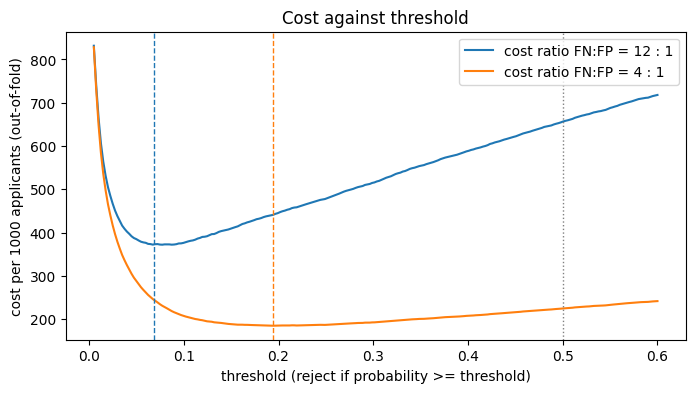

,best_threshold,bayes_threshold,cost_per_1000_pooled_oof,rejected_share
FN:FP = 12:1,0.0689,0.0769,371.4750,0.2304
FN:FP = 4:1,0.1946,0.2000,184.9000,0.0916


In [14]:
grid = np.linspace(0.005, 0.6, 240)
curves = {}
for label, c_fn in [(f"{COST_FN:g} : {COST_FP:g}", COST_FN), (f"{M.alt_cost_fn:g} : {COST_FP:g}", M.alt_cost_fn)]:
    curves[label] = [cm.per_1000(cm.decision_cost(y_train, final_cv.oof >= t, c_fn, COST_FP), len(train)) for t in grid]
alt_threshold, alt_cost = cm.best_threshold(y_train, final_cv.oof, M.alt_cost_fn, COST_FP)
fig, ax = plt.subplots(figsize=(8, 4))
for label, values in curves.items():
    ax.plot(grid, values, label=f"cost ratio FN:FP = {label}")
ax.axvline(THRESHOLD, color="C0", linestyle="--", linewidth=1)
ax.axvline(alt_threshold, color="C1", linestyle="--", linewidth=1)
ax.axvline(0.5, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("threshold (reject if probability >= threshold)"); ax.set_ylabel("cost per 1000 applicants (out-of-fold)")
ax.legend(); ax.set_title("Cost against threshold"); plt.show()
sensitivity = pd.DataFrame({
    "best_threshold": [THRESHOLD, alt_threshold],
    "bayes_threshold": [cm.bayes_threshold(COST_FN, COST_FP), cm.bayes_threshold(M.alt_cost_fn, COST_FP)],
    "cost_per_1000_pooled_oof": [cm.per_1000(cm.best_threshold(y_train, final_cv.oof, COST_FN, COST_FP)[1], len(train)),
                                 cm.per_1000(alt_cost, len(train))],
    "rejected_share": [(final_cv.oof >= THRESHOLD).mean(), (final_cv.oof >= alt_threshold).mean()],
}, index=[f"FN:FP = {COST_FN:g}:{COST_FP:g}", f"FN:FP = {M.alt_cost_fn:g}:{COST_FP:g}"])
sensitivity

**حساسیت به ماتریس هزینه:** با نسبت ۴ به ۱، آستانه بهینه از 0.0689 به 0.1946 بالا می‌رود و سهم ردشده‌ها از 0.2304 به 0.0916 کم می‌شود. معنایش این است که آستانه «تنظیم فنی مدل» نیست، **یک تصمیم کسب‌وکاری** است. اگر مؤسسه هزینه‌هایش را عوض کند، باید آستانه را دوباره انتخاب کرد، حتی بدون آموزش دوباره مدل.

آستانه انتخابی من (0.0689) هم نزدیک آستانه نظری (0.0769) است، یعنی احتمال‌های HGB تقریباً کالیبره‌اند.

## ۱۰. ارزیابی نهایی روی مجموعه کنارگذاشته (فقط یک بار)

مدل نهایی را روی کل ۸۰٪ آموزش fit می‌کنم و با آستانه‌ای که در CV انتخاب کردم، روی ۲۰٪ کنارگذاشته می‌سنجم. بعد از این سلول هیچ انتخابی را عوض نمی‌کنم.

In [15]:
final_model = make_final().fit(train, y_train)
test_proba = final_model.predict_proba(test)[:, 1]
report = cm.classification_report(y_test, test_proba, THRESHOLD, COST_FN, COST_FP)
approve_all = cm.classification_report(y_test, np.zeros(len(test)), THRESHOLD, COST_FN, COST_FP)
at_half = cm.classification_report(y_test, test_proba >= 0.5, 0.5, COST_FN, COST_FP)
print(f"FINAL: expected cost per 1000 applicants = {report['cost_per_1000']:.1f} "
      f"(CV: {fold_costs.mean():.1f} ± {fold_costs.std(ddof=1):.1f}; baseline on test: "
      f"{cm.per_1000(cm.decision_cost(y_test, cm.add_features(test)['total_past_due'].fillna(99) >= best_k, COST_FN, COST_FP), len(test)):.1f})")
confusion = pd.DataFrame([[report["tn"], report["fp"]], [report["fn"], report["tp"]]],
                         index=["actual: repaid", "actual: default"], columns=["predicted: approve", "predicted: reject"])
display(confusion)
pd.DataFrame({"chosen threshold": report, "approve everyone": {**approve_all, "roc_auc": np.nan, "pr_auc": np.nan},
              "same model at 0.5": {k: at_half[k] for k in at_half if k not in ("roc_auc", "pr_auc")}}).T[
    ["threshold", "tn", "fp", "fn", "tp", "precision", "recall", "f1", "roc_auc", "pr_auc", "accuracy", "cost_per_1000"]]

FINAL: expected cost per 1000 applicants = 366.1 (CV: 371.5 ± 10.6; baseline on test: 412.8)


,predicted: approve,predicted: reject
actual: repaid,22580,5415
actual: default,464,1541


,threshold,tn,fp,fn,tp,precision,recall,f1,roc_auc,pr_auc,accuracy,cost_per_1000
chosen threshold,0.0689,22580.0000,5415.0000,464.0000,1541.0000,0.2215,0.7686,0.3439,0.8678,0.4052,0.8040,366.1000
approve everyone,0.0689,27995.0000,0.0000,2005.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.9332,802.0000
same model at 0.5,0.5000,27740.0000,255.0000,1628.0000,377.0000,0.5965,0.1880,0.2859,NaN,NaN,0.9372,659.7000


**نتیجه نهایی: هزینه مورد انتظار 366.1 واحد به ازای هر ۱۰۰۰ متقاضی.** این عدد داخل بازه CV است (371.5 ± 10.6)، پس فاصله معناداری بین اعتبارسنجی و آزمون نهایی ندیدم و نتیجه پایدار است. قاعده دستی خط مبنا روی همین داده 412.8 هزینه دارد.

**چرا Accuracy گمراه‌کننده است:**
- «همه را تأیید کن» بدون هیچ یادگیری Accuracy برابر 0.9332 دارد، ولی هزینه‌اش 802.0 است.
- همین مدل در آستانه پیش‌فرض 0.5 Accuracy برابر 0.9372 دارد، با هزینه 659.7.
- مدل من با Accuracy برابر 0.8040 ارزان‌ترین تصمیم است. من عمداً افراد سالم بیشتری را رد می‌کنم (هر کدام ۱ واحد) تا نکول‌های ۱۲ واحدی را بگیرم.

## ۱۱. تفسیر: پنج ویژگی مؤثرتر، انصاف و «کجا می‌شکند؟»

اهمیت ویژگی‌ها را با **permutation importance** روی مجموعه نهایی می‌سنجم: هر ستون ورودی را به‌هم می‌ریزم و افت PR-AUC را اندازه می‌گیرم. این روش به نوع مدل وابسته نیست و روی ستون‌های اصلی کار می‌کند.

پنج ستون مؤثرتر با شهود اعتباری می‌خواند:
- سابقه تأخیر جدی (`past_due_90`) مهم‌ترین است.
- بعد از آن استفاده زیاد از سقف کارت (`revolving_utilization`) است.
- بعد دو نوع تأخیر کوتاه‌تر، و در آخر سن.

این‌ها نشانه‌های شناخته‌شده فشار مالی‌اند.

In [16]:
inputs = [c for c in cm.BASE_NUMERIC + cm.CATEGORICAL]
importance = permutation_importance(final_model, test, y_test, scoring="average_precision", n_repeats=3,
                                    random_state=SEED, n_jobs=1, max_samples=1.0)
top = pd.DataFrame({"pr_auc_drop_mean": importance.importances_mean, "pr_auc_drop_std": importance.importances_std},
                   index=test.columns).loc[[c for c in test.columns if c in inputs]].sort_values("pr_auc_drop_mean", ascending=False)
top.head(5)

,pr_auc_drop_mean,pr_auc_drop_std
past_due_90,0.1044,0.0011
revolving_utilization,0.0834,0.0028
past_due_30_59,0.0495,0.0003
past_due_60_89,0.0311,0.0013
age,0.0192,0.0042


In [17]:
segments = test.assign(proba=test_proba, reject=test_proba >= THRESHOLD, band=cm.age_band(test["age"]))
def segment_table(groups):
    rows = {}
    for name, part in segments.groupby(groups, observed=True):
        y, r = part[TARGET].to_numpy(), part["reject"].to_numpy()
        rows[name] = {"applicants": len(part), "default_rate": y.mean(), "rejected_share": r.mean(),
                      "recall": (r & (y == 1)).sum() / max((y == 1).sum(), 1),
                      "false_reject_rate": (r & (y == 0)).sum() / max((y == 0).sum(), 1),
                      "roc_auc": cm.roc_auc_score(y, part["proba"]) if 0 < y.sum() < len(y) else np.nan,
                      "cost_per_1000": cm.per_1000(cm.decision_cost(y, r, COST_FN, COST_FP), len(part))}
    return pd.DataFrame(rows).T
fairness = segment_table("band")
fairness

,applicants,default_rate,rejected_share,recall,false_reject_rate,roc_auc,cost_per_1000
30-44,7820.0000,0.0987,0.3418,0.8174,0.2897,0.8474,477.4936
45-59,10747.0000,0.0675,0.2490,0.7503,0.2127,0.8500,400.4839
60+,9695.0000,0.0290,0.0833,0.6014,0.0679,0.8702,204.5384
<30,1738.0000,0.1306,0.4597,0.8678,0.3984,0.8338,553.5098


**انصاف:** متریک‌ها در گروه‌های سنی یکسان نیستند. در گروه زیر ۳۰ سال، 0.3984 از افراد سالم به اشتباه رد می‌شوند؛ در گروه ۶۰ سال و بالاتر این عدد 0.0679 است. نرخ نکول پایه جوان‌ترها هم بیشتر است (0.1306 در برابر 0.0290).

برای مؤسسه یعنی:
- یک سیاست یکسان، اثر نابرابر دارد.
- استفاده از سن (که در بسیاری از قوانین وام‌دهی ویژگی حمایت‌شده است) باید حقوقی بررسی شود.
- هر گروه باید جداگانه پایش شود.

In [18]:
cases = {
    "income missing": segments["monthly_income"].isna(),
    "past-due code 96/98": segments["past_due_code"] != "none",
    "clean history, high utilization (>1)": (segments[["past_due_30_59", "past_due_60_89", "past_due_90"]].sum(axis=1) == 0)
        & (segments["past_due_code"] == "none") & (segments["revolving_utilization"] > 1),
    "very high income (top 1%)": segments["monthly_income"] > train["monthly_income"].quantile(0.99),
    "all applicants": pd.Series(True, index=segments.index),
}
breaks = pd.concat({name: segment_table(mask.map({True: "in", False: "out"})).loc[["in"]] for name, mask in cases.items()})
breaks.droplevel(1)

,applicants,default_rate,rejected_share,recall,false_reject_rate,roc_auc,cost_per_1000
income missing,6056.0000,0.0578,0.1922,0.7943,0.1553,0.8926,288.9696
past-due code 96/98,55.0000,0.5455,1.0000,1.0000,1.0000,0.6267,454.5455
"clean history, high utilization (>1)",199.0000,0.1859,0.8844,0.9459,0.8704,0.6862,829.1457
very high income (top 1%),247.0000,0.0486,0.2429,0.9167,0.2085,0.9287,246.9636
all applicants,30000.0000,0.0668,0.2319,0.7686,0.1934,0.8678,366.1000


**کجا می‌شکند؟** سه موقعیت که مدل در آن‌ها تصمیم بد می‌گیرد (عددها از جدول بالا):
1. **سابقه پاک ولی utilization بالای ۱:** این متقاضیان تأخیری ندارند ولی از سقف کارت گذشته‌اند، یعنی یک شوک تازه که هنوز در تأخیرها دیده نشده. هزینه 829.1 در هر ۱۰۰۰ و ROC-AUC فقط 0.6862 است.
2. **کدهای 96/98:** همه این متقاضیان رد می‌شوند و ROC-AUC 0.6267 است. معنای دقیق کد معلوم نیست، و اگر منبع کد تازه‌ای بسازد، مدل آن را ناشناخته می‌بیند.
3. **درآمد گمشده:** مدل فقط «میانه + پرچم» می‌بیند. متقاضی پردرآمدی که درآمدش را ثبت نکرده، برای مدل با کسی که درآمد ندارد فرقی ندارد.

جدا از این سه، داده فقط کسانی را دارد که **قبلاً وام گرفته‌اند** (سوگیری انتخاب). درباره کسانی که مؤسسه قبلاً رد می‌کرده، مدل هیچ شاهدی ندارد.

## ۱۲. ذخیره مدل و پیش‌بینی روی فایل تازه

Pipeline (ویژگی‌ها + آماده‌سازی fitشده روی آموزش + مدل) و آستانه را در `data/curated/credit/model.joblib` ذخیره می‌کنم. فرمان `data-factory predict --input <file> --output <file>` فایل تازه با همان schema `cs-training.csv` را این‌طور پردازش می‌کند:
1. با **همان قرارداد** اعتبارسنجی می‌کند.
2. در یک تراکنش آن را در `credit.scoring_batch` می‌نویسد و از **همان view** می‌خواند.
3. تراکنش را rollback می‌کند، پس هیچ قاعده‌ای دو جا نوشته نمی‌شود و چیزی در پایگاه داده نمی‌ماند.
4. احتمال و تصمیم را در فایل خروجی می‌نویسد.

برای نمایش، پنج متقاضی از مجموعه نهایی را با مقدارهای خامشان از پایگاه داده به شکل یک فایل تازه درمی‌آورم و به این فرمان می‌دهم. این CSV را فرمان پیش‌بینی می‌خواند، نه نوت‌بوک. آخر سلول بررسی می‌کنم که خروجی دقیقاً همان احتمال‌های مدل نوت‌بوک باشد.

In [19]:
from data_factory.credit_predict import predict_file
cm.save_model(M.model_file, final_model, THRESHOLD,
              {"kind": BEST_KIND, "missing": BEST_MISSING, "dropped": DROPPED, "cost_fn": COST_FN, "cost_fp": COST_FP})
sample_ids = test["applicant_id"].head(5).tolist()
with engine.connect() as connection:
    raw = pd.read_sql_query(text("SELECT * FROM credit.applicants WHERE applicant_id = ANY(:ids) ORDER BY applicant_id"),
                            connection, params={"ids": sample_ids})
source_names = {"applicant_id": "Unnamed: 0", "revolving_utilization": "RevolvingUtilizationOfUnsecuredLines", "age": "age",
                "past_due_30_59": "NumberOfTime30-59DaysPastDueNotWorse", "debt_ratio": "DebtRatio", "monthly_income": "MonthlyIncome",
                "open_credit_lines": "NumberOfOpenCreditLinesAndLoans", "past_due_90": "NumberOfTimes90DaysLate",
                "real_estate_loans": "NumberRealEstateLoansOrLines", "past_due_60_89": "NumberOfTime60-89DaysPastDueNotWorse",
                "dependents": "NumberOfDependents"}
sample_path = config.paths.work / "credit" / "sample_new_applicants.csv"
raw.drop(columns=[TARGET]).rename(columns=source_names).astype({"NumberOfDependents": "Int64"}).to_csv(
    sample_path, index=False, na_rep="NA")
scored = predict_file(config, sample_path, config.paths.work / "credit" / "sample_predictions.csv")
check = scored.merge(pd.DataFrame({"applicant_id": test["applicant_id"], "notebook_proba": test_proba}), on="applicant_id")
print("prediction path equals the notebook model:", np.allclose(check.probability, check.notebook_proba))
check

prediction path equals the notebook model: True


,applicant_id,probability,decision,notebook_proba
0,1,0.3367,reject,0.3367
1,7,0.0218,approve,0.0218
2,17,0.0062,approve,0.0062
3,18,0.0153,approve,0.0153
4,19,0.0192,approve,0.0192


## ۱۳. شناسنامه مدل (Model Card)

- **کار مدل:** احتمال نکول جدی (۹۰ روز تأخیر یا بیشتر) در دو سال آینده را برای متقاضی وام تخمین می‌زند، و با آستانه 0.0689 که هزینه ۱۲ به ۱ را کمینه می‌کند، «تأیید» یا «رد» پیشنهاد می‌دهد.
- **داده آموزش:** Kaggle «Give Me Some Credit»، ۱۲۰٬۰۰۰ متقاضی (۸۰٪ داده)، نرخ نکول 6.68%. داده زمان، کشور و تعریف دقیق محصول ندارد.
- **چه کاری نمی‌تواند:**
  - مبلغ وام یا زیان واقعی را نمی‌بیند؛ هزینه‌ها ثابت فرض شده‌اند.
  - تغییر اقتصاد در طول زمان را نمی‌بیند.
  - احتمال‌هایش برای قیمت‌گذاری وام، کالیبره‌سازی جداگانه لازم دارند.
- **برای چه کسانی نباید استفاده شود:**
  - متقاضیان بدون سابقه اعتباری، و کسب‌وکارها.
  - کشورها یا دوره‌های زمانی دیگر.
  - جمعیتی که مؤسسه قبلاً رد می‌کرده و در داده نیست.
  - همچنین تا وقتی استفاده از سن حقوقی بررسی نشده، نباید به کار برود.

In [20]:
engine.dispose()
print(f"notebook runtime: {(time.perf_counter() - NOTEBOOK_STARTED) / 60:.1f} minutes")

notebook runtime: 7.5 minutes
